# Proyecto A: Sistema de Predicción de Riesgo Crediticio

## Análisis Exploratorio de Datos (EDA)

Este notebook presenta el análisis exploratorio del conjunto de datos German Credit.
El objetivo es comprender la estructura de los datos, revisar su calidad y analizar
las variables relacionadas con la clasificación del riesgo crediticio.
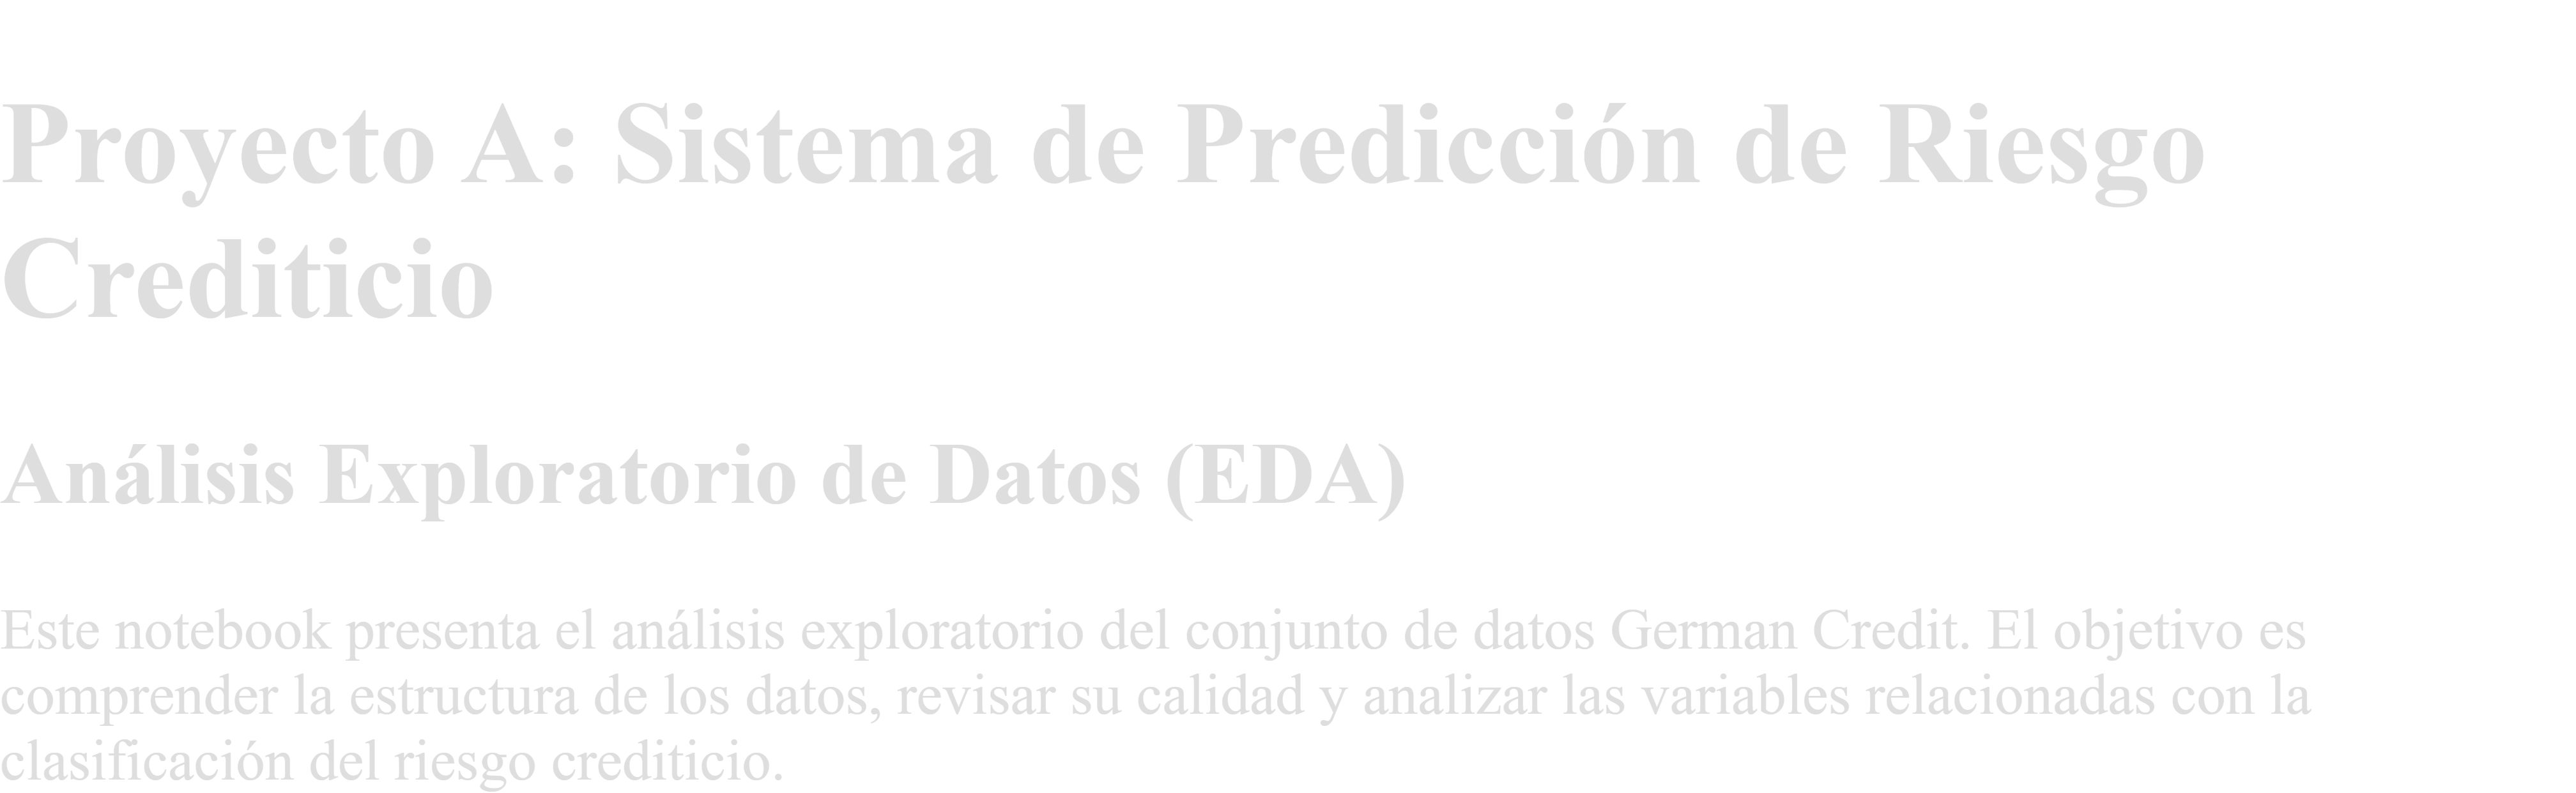
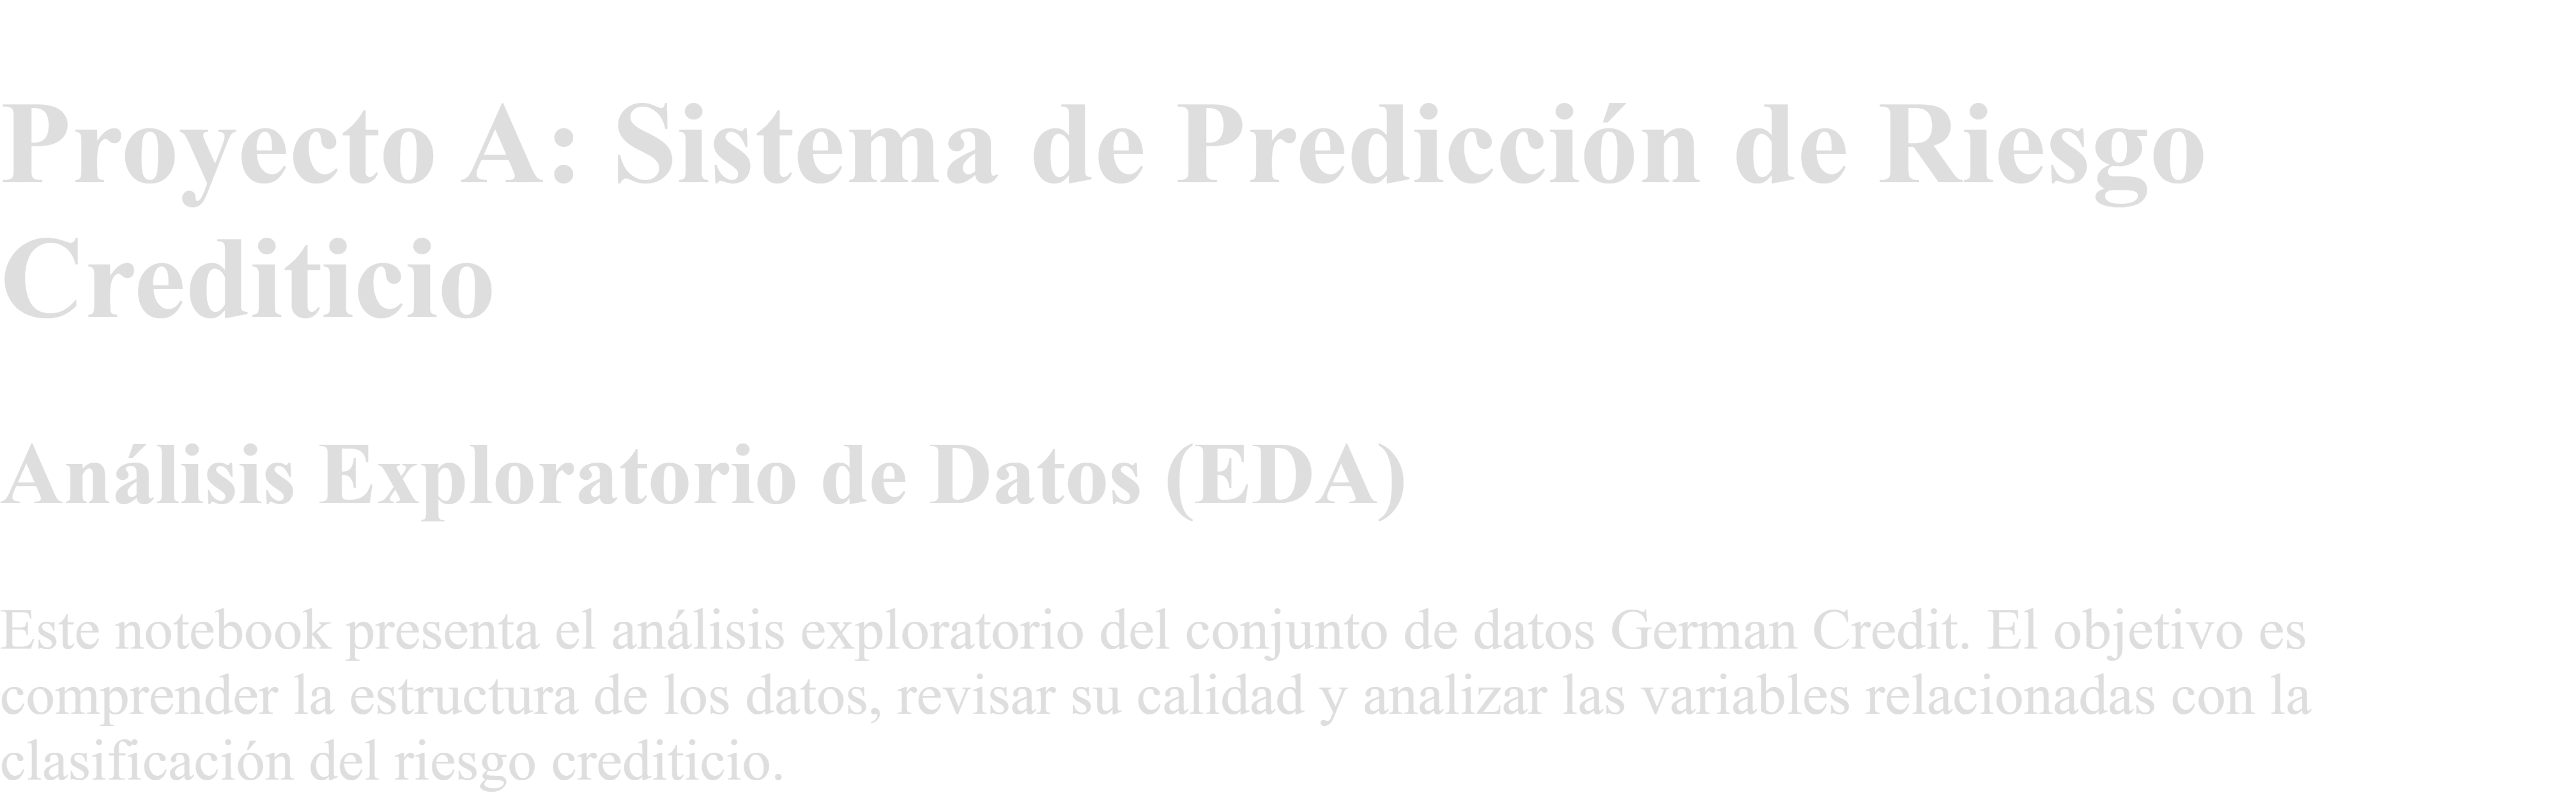

# 1. Importación de librerías

In [1]:
# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Importación de la fuente de datos

El conjunto de datos German Credit contiene información de 1.000 clientes.

Cada registro incluye 20 variables relacionadas con la situación personal,
laboral y crediticia del cliente, además de una variable de salida denominada
`clase`.

La variable `clase` utiliza la siguiente codificación:

- `1`: crédito bueno.
- `2`: crédito malo.

In [2]:
# Nombres de las columnas según la documentación oficial del dataset

columnas = [
    "estado_cuenta",
    "duracion_meses",
    "historial_crediticio",
    "proposito",
    "monto_credito",
    "cuenta_ahorros",
    "antiguedad_empleo",
    "tasa_cuotas",
    "estado_personal",
    "otros_deudores",
    "tiempo_residencia",
    "propiedad",
    "edad",
    "otros_planes_pago",
    "vivienda",
    "creditos_existentes",
    "trabajo",
    "personas_dependientes",
    "telefono",
    "trabajador_extranjero",
    "clase"
]

In [3]:
# Lectura del dataset original

df = pd.read_csv(
    "../data/raw/german.data",
    sep=r"\s+",
    header=None,
    names=columnas
)

In [4]:
# Visualización de los primeros registros

df.head()

,estado_cuenta,duracion_meses,historial_crediticio,proposito,monto_credito,cuenta_ahorros,antiguedad_empleo,tasa_cuotas,estado_personal,otros_deudores,...,propiedad,edad,otros_planes_pago,vivienda,creditos_existentes,trabajo,personas_dependientes,telefono,trabajador_extranjero,clase
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## 3. Análisis de Datos (EDA)

### 3.1 Información general del dataset

En esta sección se revisan las dimensiones, los tipos de datos y la calidad inicial del conjunto de datos.

In [5]:
# Cantidad de filas y columnas del dataset
df.shape

(1000, 21)

In [6]:
# Información general del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   estado_cuenta          1000 non-null   str  
 1   duracion_meses         1000 non-null   int64
 2   historial_crediticio   1000 non-null   str  
 3   proposito              1000 non-null   str  
 4   monto_credito          1000 non-null   int64
 5   cuenta_ahorros         1000 non-null   str  
 6   antiguedad_empleo      1000 non-null   str  
 7   tasa_cuotas            1000 non-null   int64
 8   estado_personal        1000 non-null   str  
 9   otros_deudores         1000 non-null   str  
 10  tiempo_residencia      1000 non-null   int64
 11  propiedad              1000 non-null   str  
 12  edad                   1000 non-null   int64
 13  otros_planes_pago      1000 non-null   str  
 14  vivienda               1000 non-null   str  
 15  creditos_existentes    1000 non-null   int64
 16  

In [7]:
# Verificación de valores nulos
df.isnull().sum()

estado_cuenta            0
duracion_meses           0
historial_crediticio     0
proposito                0
monto_credito            0
cuenta_ahorros           0
antiguedad_empleo        0
tasa_cuotas              0
estado_personal          0
otros_deudores           0
tiempo_residencia        0
propiedad                0
edad                     0
otros_planes_pago        0
vivienda                 0
creditos_existentes      0
trabajo                  0
personas_dependientes    0
telefono                 0
trabajador_extranjero    0
clase                    0
dtype: int64

In [8]:
# Cantidad de registros duplicados
df.duplicated().sum()

np.int64(0)

In [9]:
print("Cantidad de registros:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])
print("Valores nulos totales:", df.isnull().sum().sum())
print("Registros duplicados:", df.duplicated().sum())

Cantidad de registros: 1000
Cantidad de columnas: 21
Valores nulos totales: 0
Registros duplicados: 0


### Conclusión de la revisión inicial

El conjunto de datos contiene 1.000 registros y 21 columnas, correspondientes
a 20 variables de entrada y una variable objetivo.

No se encontraron valores nulos ni registros duplicados. Por lo tanto, no es
necesario eliminar registros durante esta etapa del análisis.

## 3.2 Estadísticas descriptivas

Se analizan las variables numéricas para conocer sus valores mínimos, máximos,
promedios y distribución general.

In [10]:
# Estadísticas descriptivas de las variables numéricas
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
duracion_meses,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
monto_credito,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
tasa_cuotas,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
tiempo_residencia,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
edad,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
creditos_existentes,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
personas_dependientes,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
clase,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0


### Interpretación de las estadísticas descriptivas

La duración de los créditos se encuentra entre 4 y 72 meses, con un promedio
aproximado de 21 meses. El monto del crédito varía entre 250 y 18.424, mientras
que su promedio es aproximadamente 3.271.

La edad de los clientes se encuentra entre 19 y 75 años, con un promedio
aproximado de 36 años. La mayoría de los clientes tiene un crédito existente
y una persona dependiente.

La variable `clase` aparece en la tabla porque está representada mediante
números. Sin embargo, debe interpretarse como una variable categórica:

- `1`: crédito bueno.
- `2`: crédito malo.
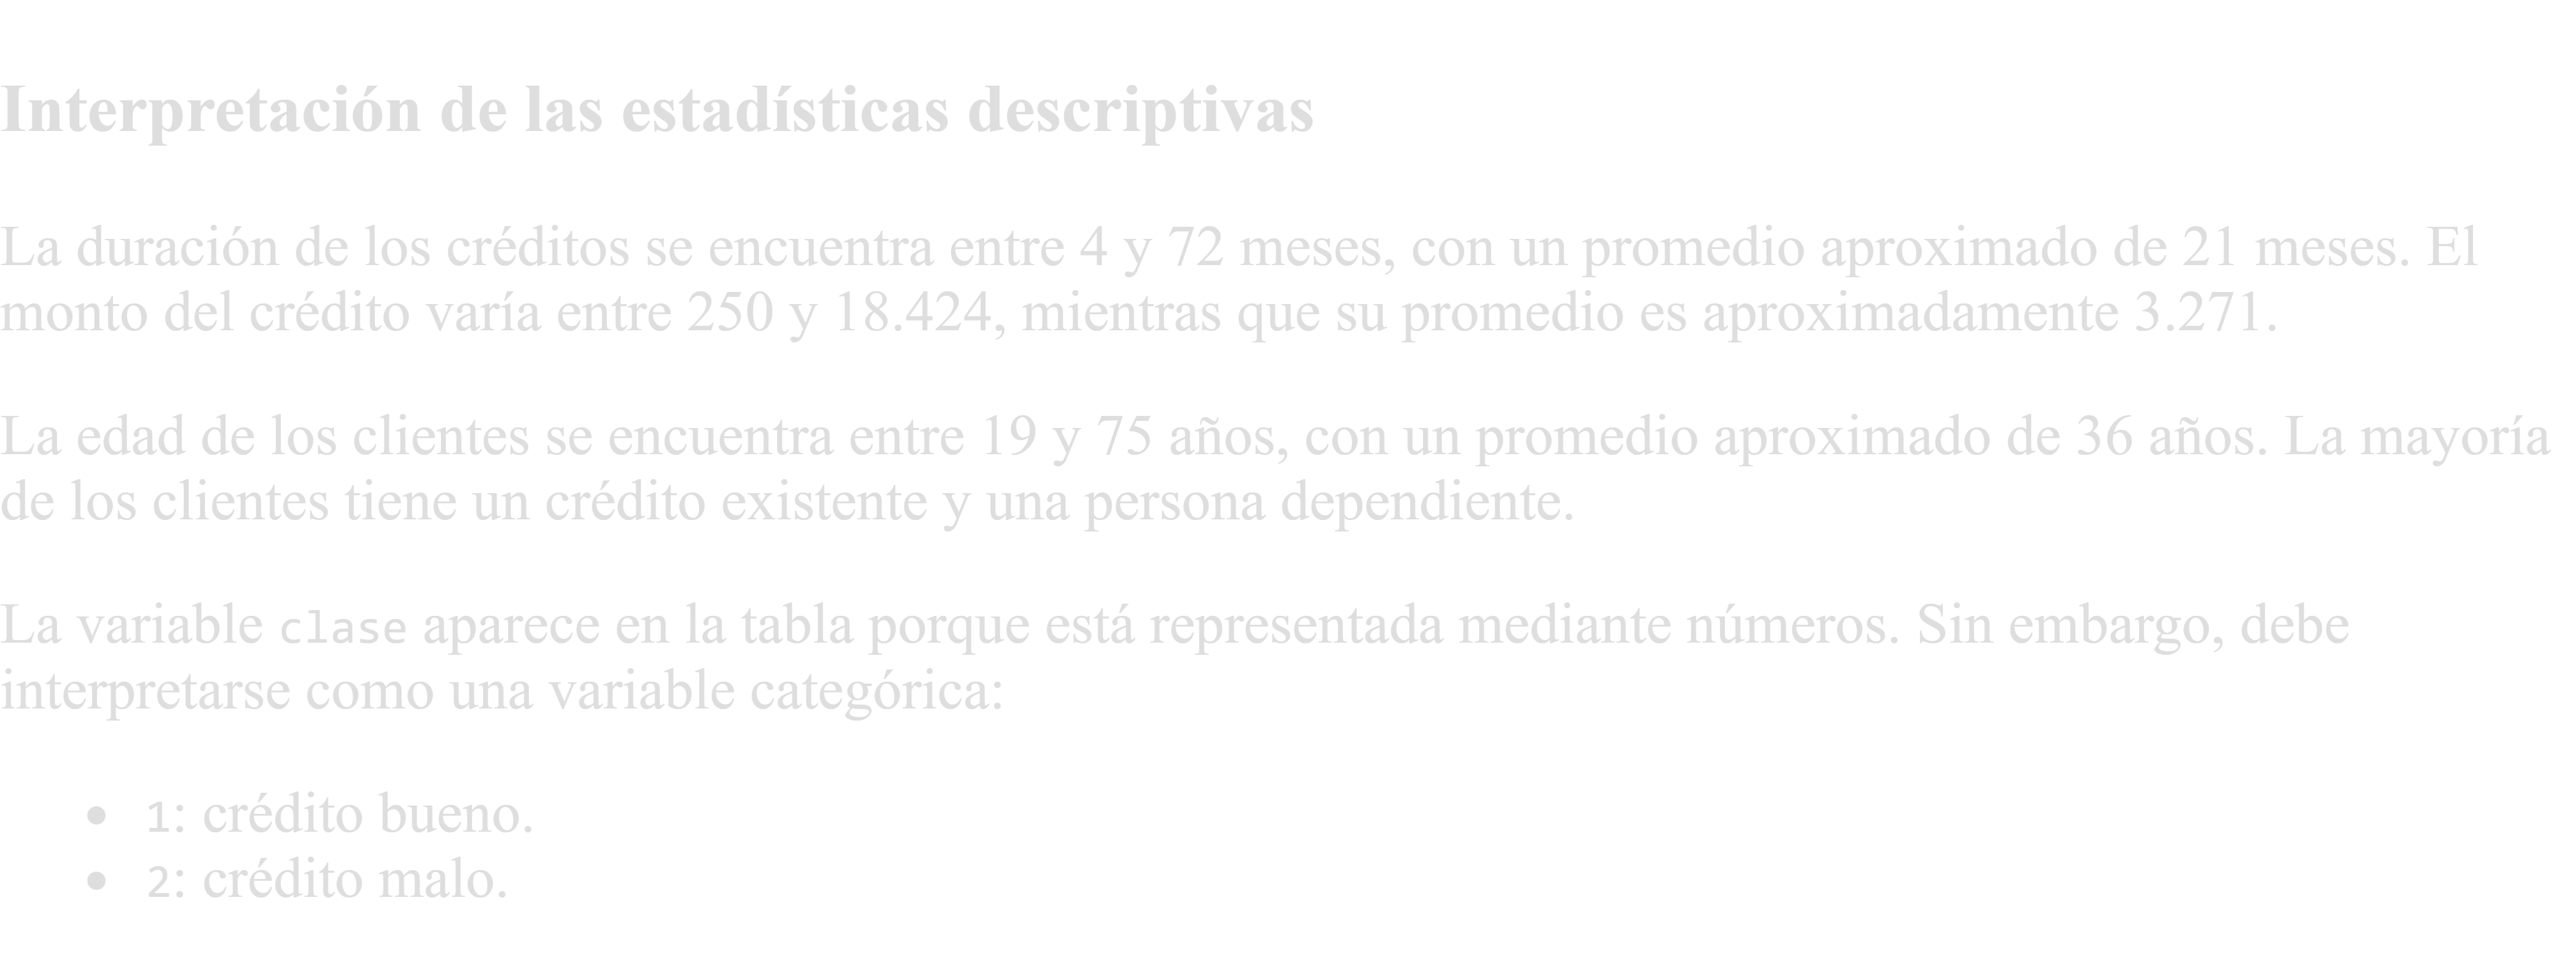

## 3.3 Análisis de la variable objetivo

Se analiza la distribución de la variable `clase` para conocer la cantidad
de créditos buenos y malos presentes en el dataset.

In [11]:
# Cantidad de registros por clase
df["clase"].value_counts()

clase
1    700
2    300
Name: count, dtype: int64

In [12]:
# Porcentaje de registros por clase
df["clase"].value_counts(normalize=True) * 100

clase
1    70.0
2    30.0
Name: proportion, dtype: float64

### Interpretación de la variable objetivo

El dataset contiene 700 créditos clasificados como buenos, equivalentes al
70 % de los registros, y 300 créditos clasificados como malos, equivalentes
al 30 %.

La variable objetivo presenta un desbalance de clases, debido a que existen
más registros de créditos buenos que de créditos malos. Por esta razón, la
evaluación del modelo no debe basarse únicamente en la exactitud, sino también
en métricas como precisión, recall, F1-score y la matriz de confusión.

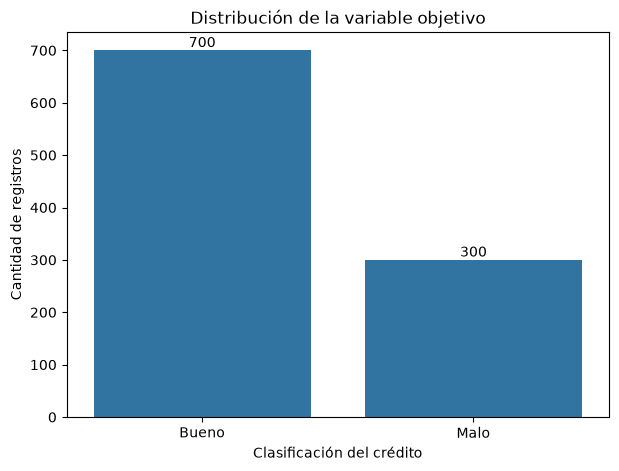

In [13]:
# Gráfico de la distribución de la variable objetivo

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="clase"
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Clasificación del crédito")
plt.ylabel("Cantidad de registros")
plt.xticks(
    ticks=[0, 1],
    labels=["Bueno", "Malo"]
)

for barra in ax.containers:
    ax.bar_label(barra)

plt.show()

El gráfico confirma que la clase correspondiente a los créditos buenos es la
más frecuente, con 700 registros, mientras que los créditos malos cuentan con
300 registros.

Este desbalance deberá considerarse durante la evaluación de los modelos para
evitar seleccionar una configuración que obtenga una exactitud alta solamente
por favorecer la clase mayoritaria.

## 3.4 Análisis de las variables numéricas

Se analiza la distribución de las principales variables numéricas del dataset:
duración del crédito, monto solicitado y edad del cliente.

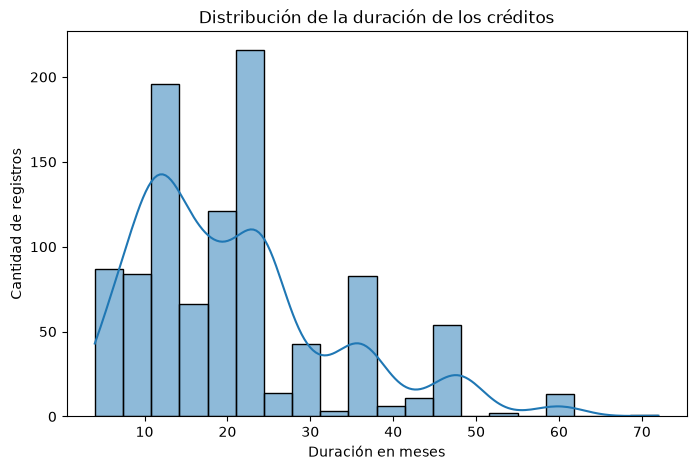

In [14]:
# Distribución de la duración de los créditos

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="duracion_meses",
    bins=20,
    kde=True
)

plt.title("Distribución de la duración de los créditos")
plt.xlabel("Duración en meses")
plt.ylabel("Cantidad de registros")

plt.show()

### Interpretación de la duración

La duración de los créditos se encuentra entre 4 y 72 meses. El promedio es
aproximadamente de 21 meses y la mediana es de 18 meses.

La mayor parte de los créditos presenta una duración cercana a los valores
centrales, mientras que existen menos créditos con duraciones muy extensas.

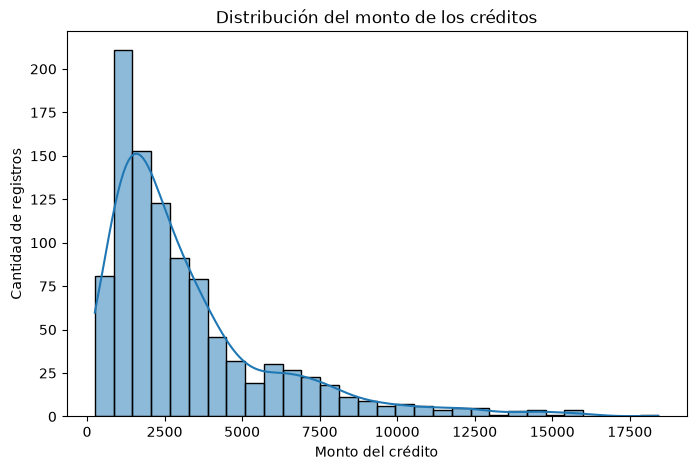

In [15]:
# Distribución del monto de los créditos

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="monto_credito",
    bins=30,
    kde=True
)

plt.title("Distribución del monto de los créditos")
plt.xlabel("Monto del crédito")
plt.ylabel("Cantidad de registros")

plt.show()

### Interpretación del monto

El monto de los créditos se encuentra entre 250 y 18.424. El promedio es
aproximadamente de 3.271, mientras que la mediana es de 2.319,5.

La diferencia entre el promedio y la mediana indica que algunos créditos con
montos elevados aumentan el valor del promedio. La mayoría de los créditos se
concentra en montos inferiores, mientras que existen pocos casos con montos
considerablemente altos.

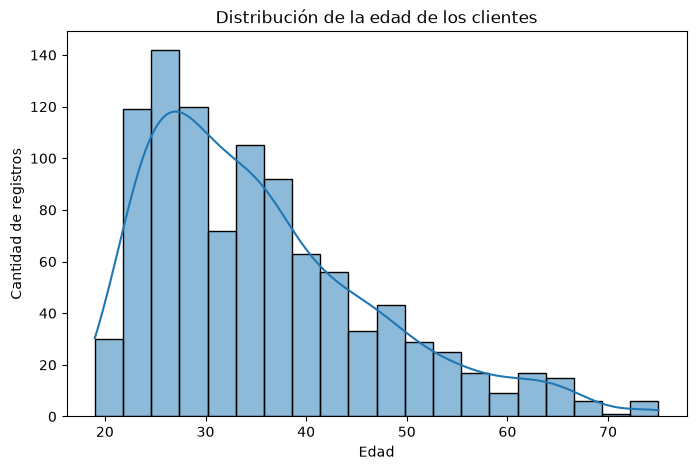

In [16]:
# Distribución de la edad de los clientes

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="edad",
    bins=20,
    kde=True
)

plt.title("Distribución de la edad de los clientes")
plt.xlabel("Edad")
plt.ylabel("Cantidad de registros")

plt.show()

### Interpretación de la edad

La edad de los clientes se encuentra entre 19 y 75 años. La edad promedio es
aproximadamente de 36 años y la mediana es de 33 años.

La mayoría de los clientes se concentra en las edades más cercanas al promedio,
mientras que se observa una cantidad menor de clientes en las edades má
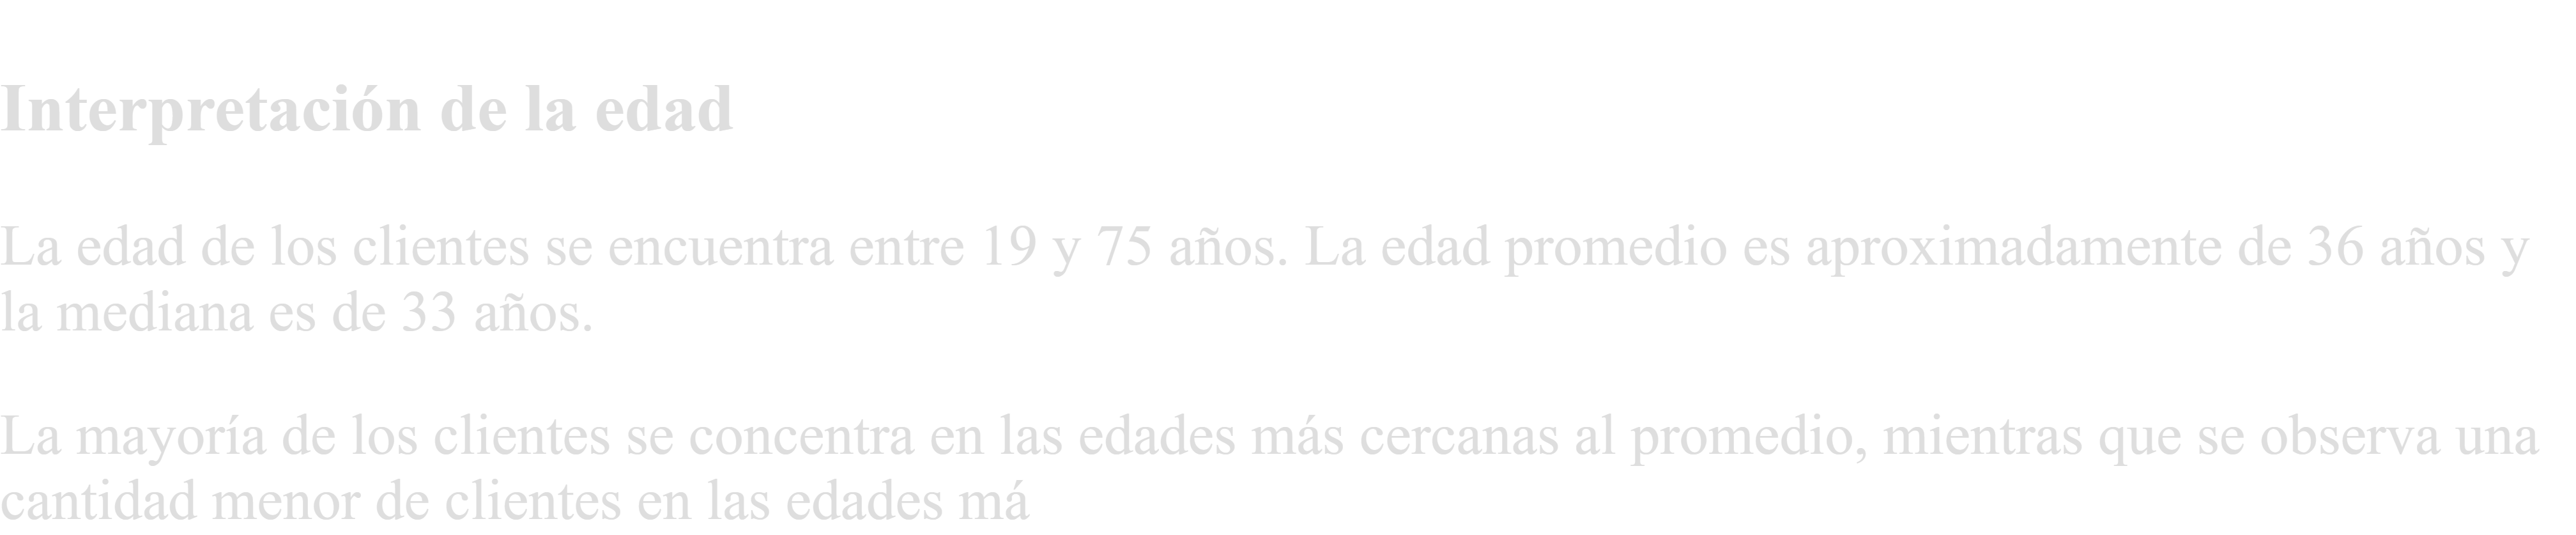

### 3.4.2 Comparación conjunta de las principales variables numéricas

Como complemento a los gráficos individuales, se presenta una comparación
conjunta de la duración, el monto y la edad.

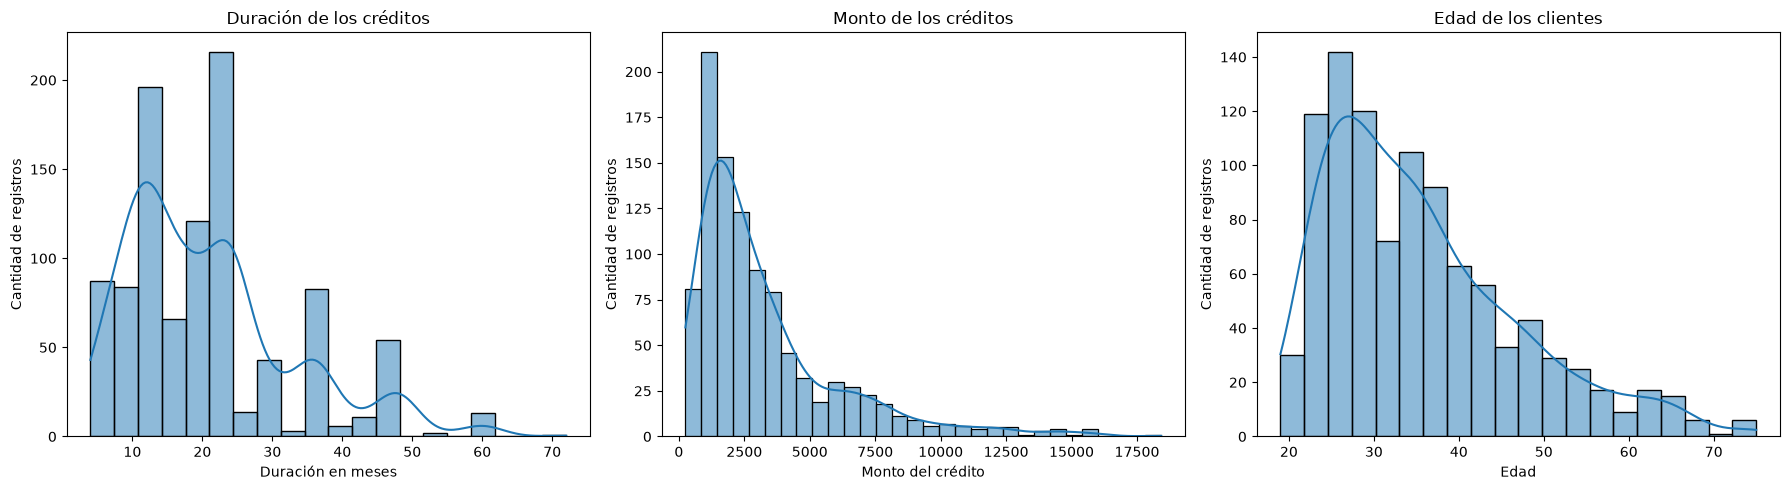

In [17]:
# Comparación de las principales variables numéricas

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=df,
    x="duracion_meses",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Duración de los créditos")
axes[0].set_xlabel("Duración en meses")
axes[0].set_ylabel("Cantidad de registros")


sns.histplot(
    data=df,
    x="monto_credito",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Monto de los créditos")
axes[1].set_xlabel("Monto del crédito")
axes[1].set_ylabel("Cantidad de registros")


sns.histplot(
    data=df,
    x="edad",
    bins=20,
    kde=True,
    ax=axes[2]
)

axes[2].set_title("Edad de los clientes")
axes[2].set_xlabel("Edad")
axes[2].set_ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()

### Comparación entre ambos enfoques

La figura conjunta utiliza subgráficos para mostrar las tres distribuciones
en una sola visualización. Esto facilita su comparación.

## 3.5 Relación de las variables numéricas con la clase

Se comparan la duración, el monto y la edad según la clasificación del crédito.

Los gráficos permiten observar diferencias entre los créditos buenos y malos,
pero no demuestran que una variable sea la causa directa de la clasificación.

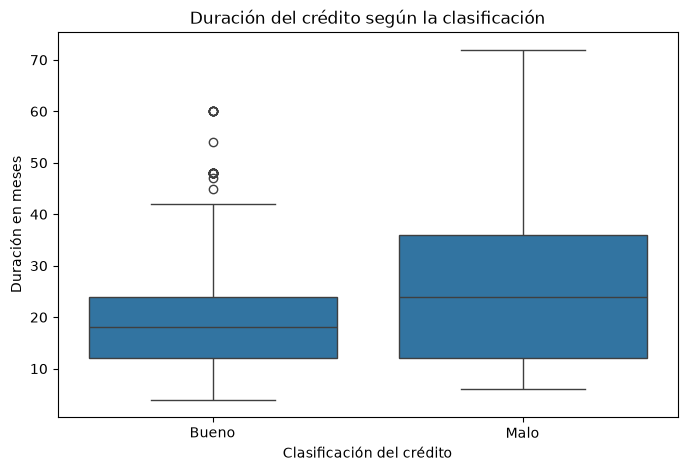

In [18]:
# Duración del crédito según la clase

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="clase",
    y="duracion_meses"
)

plt.title("Duración del crédito según la clasificación")
plt.xlabel("Clasificación del crédito")
plt.ylabel("Duración en meses")

plt.xticks(
    ticks=[0, 1],
    labels=["Bueno", "Malo"]
)

plt.show()

In [19]:
# Promedio y mediana de la duración según la clase
df.groupby("clase")["duracion_meses"].agg(["mean", "median"])

,mean,median
clase,,
1,19.207143,18.0
2,24.860000,24.0


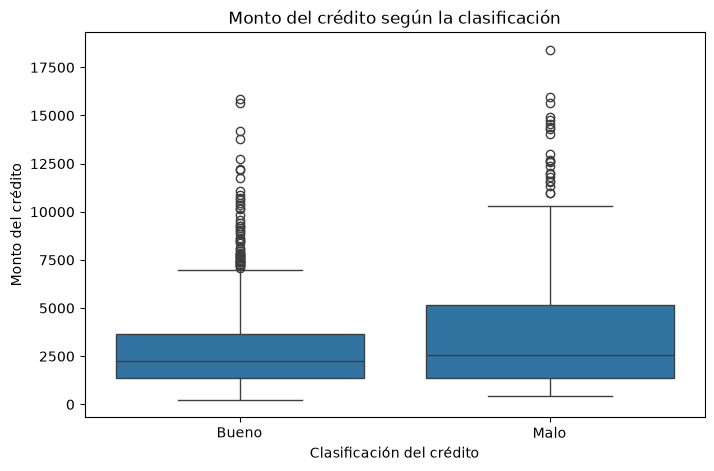

In [20]:
# Monto del crédito según la clase

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="clase",
    y="monto_credito"
)

plt.title("Monto del crédito según la clasificación")
plt.xlabel("Clasificación del crédito")
plt.ylabel("Monto del crédito")

plt.xticks(
    ticks=[0, 1],
    labels=["Bueno", "Malo"]
)

plt.show()

In [21]:
# Promedio y mediana del monto según la clase
df.groupby("clase")["monto_credito"].agg(["mean", "median"])

,mean,median
clase,,
1,2985.457143,2244.0
2,3938.126667,2574.5


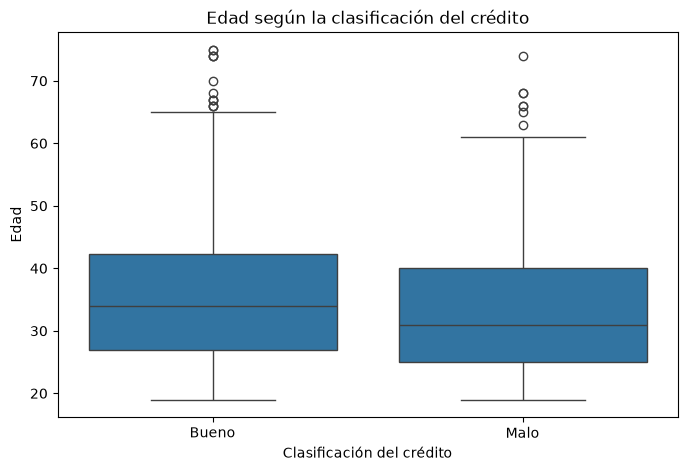

In [22]:
# Edad de los clientes según la clase

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="clase",
    y="edad"
)

plt.title("Edad según la clasificación del crédito")
plt.xlabel("Clasificación del crédito")
plt.ylabel("Edad")

plt.xticks(
    ticks=[0, 1],
    labels=["Bueno", "Malo"]
)

plt.show()

In [23]:
# Promedio y mediana de la edad según la clase
df.groupby("clase")["edad"].agg(["mean", "median"])

,mean,median
clase,,
1,36.224286,34.0
2,33.963333,31.0


### Comparación conjunta de variables numéricas por clase
Como cOmplemento a los gráficos individuales, se presentan las tres
comparaciones en una misma figura para facilitar su lectura

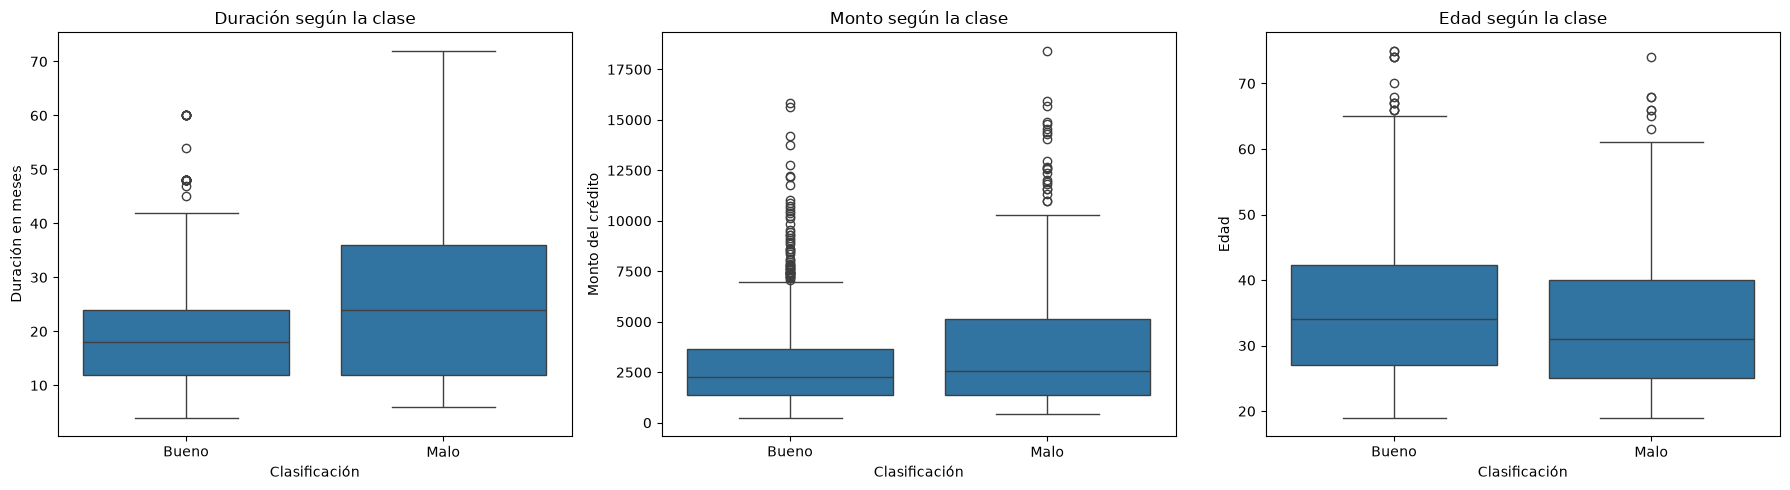

In [24]:
# Recomendación de Aura:
# Comparación conjunta de variables numéricas según la clase

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Duración
sns.boxplot(
    data=df,
    x="clase",
    y="duracion_meses",
    ax=axes[0]
)

axes[0].set_title("Duración según la clase")
axes[0].set_xlabel("Clasificación")
axes[0].set_ylabel("Duración en meses")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Bueno", "Malo"])


# Monto
sns.boxplot(
    data=df,
    x="clase",
    y="monto_credito",
    ax=axes[1]
)

axes[1].set_title("Monto según la clase")
axes[1].set_xlabel("Clasificación")
axes[1].set_ylabel("Monto del crédito")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Bueno", "Malo"])


# Edad
sns.boxplot(
    data=df,
    x="clase",
    y="edad",
    ax=axes[2]
)

axes[2].set_title("Edad según la clase")
axes[2].set_xlabel("Clasificación")
axes[2].set_ylabel("Edad")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Bueno", "Malo"])

plt.tight_layout()
plt.show()

In [25]:
# Resumen de las variables numéricas según la clase

resumen_clase = df.groupby("clase")[
    ["duracion_meses", "monto_credito", "edad"]
].agg(["mean", "median"])

resumen_clase

duracion_meses        monto_credito               edad       
                mean median          mean  median       mean median
clase                                                              
1          19.207143   18.0   2985.457143  2244.0  36.224286   34.0
2          24.860000   24.0   3938.126667  2574.5  33.963333   31.0

### Interpretación de las variables numéricas según la clase

Los créditos clasificados como malos presentan una duración promedio aproximada
de 24,86 meses, mientras que los créditos buenos tienen una duración promedio
de 19,21 meses.

El monto promedio de los créditos malos es aproximadamente 3.938,13, superior
al promedio de 2.985,46 observado en los créditos buenos. También se observan
varios valores atípicos relacionados con montos elevados.

La edad promedio de los clientes con créditos buenos es aproximadamente
36,22 años, mientras que en los créditos malos es de 33,96 años.

Estos resultados muestran relaciones entre las variables numéricas y la
clasificación del crédito. Sin embargo, no demuestran que la duración, el monto
o la edad sean por sí solos la causa de una clasificación buena o mala.

## 3.6 Análisis de las variables categóricas

Se analiza la frecuencia de algunas variables categóricas importantes del
dataset, como el estado de la cuenta corriente, el historial crediticio,
el propósito del crédito y la cuenta de ahorros.

In [26]:
# Cantidad de registros según el estado de la cuenta corriente

df["estado_cuenta"].value_counts().sort_index()

estado_cuenta
A11    274
A12    269
A13     63
A14    394
Name: count, dtype: int64

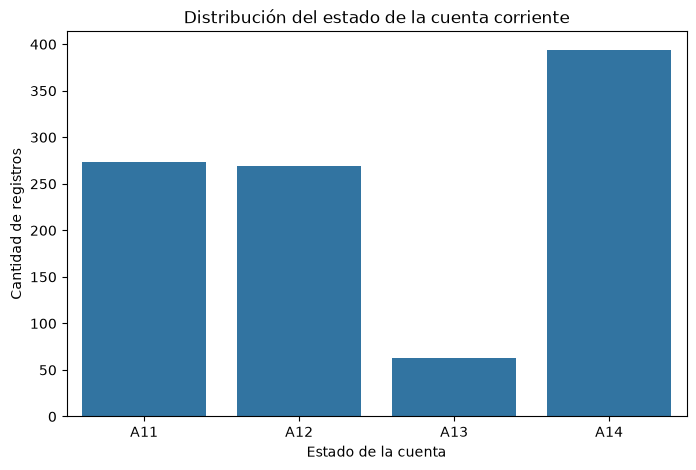

In [27]:
# Distribución del estado de la cuenta corriente

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="estado_cuenta",
    order=sorted(df["estado_cuenta"].unique())
)

plt.title("Distribución del estado de la cuenta corriente")
plt.xlabel("Estado de la cuenta")
plt.ylabel("Cantidad de registros")

plt.show()

### Interpretación del estado de la cuenta

La variable `estado_cuenta` describe la situación de la cuenta corriente del
cliente mediante cuatro categorías:

- `A11`: saldo menor que 0.
- `A12`: saldo entre 0 y 200.
- `A13`: saldo igual o mayor que 200.
- `A14`: sin cuenta corriente.

El gráfico permite identificar cuáles condiciones de cuenta corriente aparecen
con mayor frecuencia en el dataset.

## 3.6.1 Estado de cuenta relacionado con la clase

In [28]:
# Estado de la cuenta corriente según la clase

tabla_estado_cuenta = pd.crosstab(
    df["estado_cuenta"],
    df["clase"]
)

tabla_estado_cuenta.columns = ["Bueno", "Malo"]

tabla_estado_cuenta

,Bueno,Malo
estado_cuenta,,
A11,139,135
A12,164,105
A13,49,14
A14,348,46


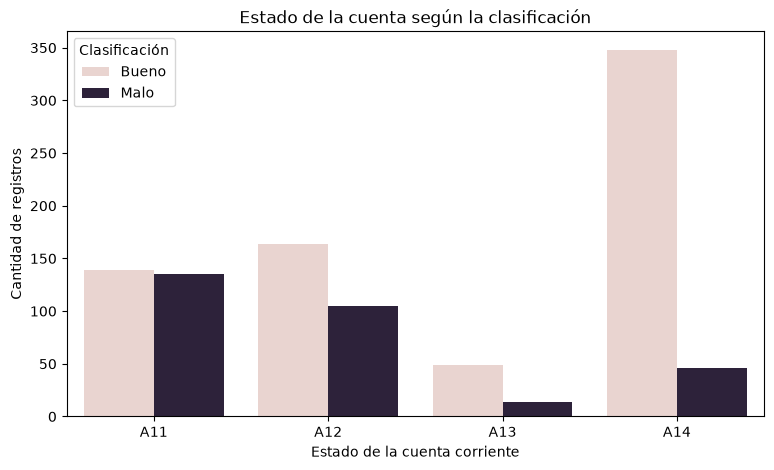

In [29]:
# Estado de la cuenta corriente según la clasificación del crédito

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="estado_cuenta",
    hue="clase",
    order=sorted(df["estado_cuenta"].unique())
)

plt.title("Estado de la cuenta según la clasificación")
plt.xlabel("Estado de la cuenta corriente")
plt.ylabel("Cantidad de registros")

plt.legend(
    title="Clasificación",
    labels=["Bueno", "Malo"]
)

plt.show()

In [30]:
# Porcentaje de créditos buenos y malos dentro de cada estado de cuenta

porcentaje_estado_cuenta = pd.crosstab(
    df["estado_cuenta"],
    df["clase"],
    normalize="index"
) * 100

porcentaje_estado_cuenta.columns = ["Bueno (%)", "Malo (%)"]

porcentaje_estado_cuenta.round(2)

,Bueno (%),Malo (%)
estado_cuenta,,
A11,50.73,49.27
A12,60.97,39.03
A13,77.78,22.22
A14,88.32,11.68


### Interpretación del estado de la cuenta según la clase

La categoría `A11`, correspondiente a un saldo menor que 0, presenta la mayor
proporción de créditos malos, con un 49,27 %. En esta categoría se observan
139 créditos buenos y 135 créditos malos.

En la categoría `A12`, saldo entre 0 y 200, los créditos malos representan
el 39,03 %. Para `A13`, saldo igual o mayor que 200, esta proporción disminuye
al 22,22 %.

La categoría `A14`, correspondiente a clientes sin cuenta corriente, presenta
la menor proporción de créditos malos, con un 11,68 %.

Estos resultados muestran una relación entre el estado de la cuenta corriente
y la clasificación del crédito dentro del dataset. Sin embargo, no demuestran
que esta variable sea por sí sola la causa de una clasificación buena o mala.

## 3.6.2 Historial crediticio

In [31]:
# Cantidad de registros según el historial crediticio

df["historial_crediticio"].value_counts().sort_index()

historial_crediticio
A30     40
A31     49
A32    530
A33     88
A34    293
Name: count, dtype: int64

### Historial crediticio

La variable `historial_crediticio` utiliza las siguientes categorías:

- `A30`: no se han solicitado créditos o todos fueron pagados correctamente.
- `A31`: todos los créditos en este banco fueron pagados correctamente.
- `A32`: créditos existentes pagados correctamente hasta el momento.
- `A33`: retrasos en pagos anteriores.
- `A34`: cuenta crítica o existencia de otros créditos.

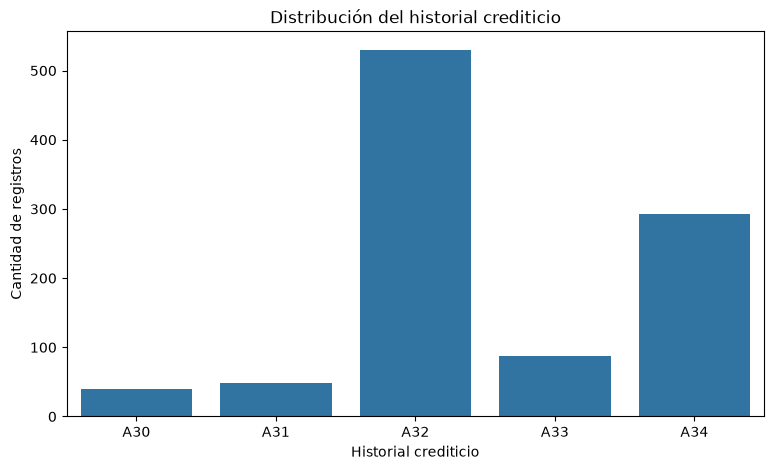

In [32]:
# Distribución del historial crediticio

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="historial_crediticio",
    order=sorted(df["historial_crediticio"].unique())
)

plt.title("Distribución del historial crediticio")
plt.xlabel("Historial crediticio")
plt.ylabel("Cantidad de registros")

plt.show()

In [33]:
# Historial crediticio según la clase

tabla_historial = pd.crosstab(
    df["historial_crediticio"],
    df["clase"]
)

tabla_historial.columns = ["Bueno", "Malo"]

tabla_historial

,Bueno,Malo
historial_crediticio,,
A30,15,25
A31,21,28
A32,361,169
A33,60,28
A34,243,50


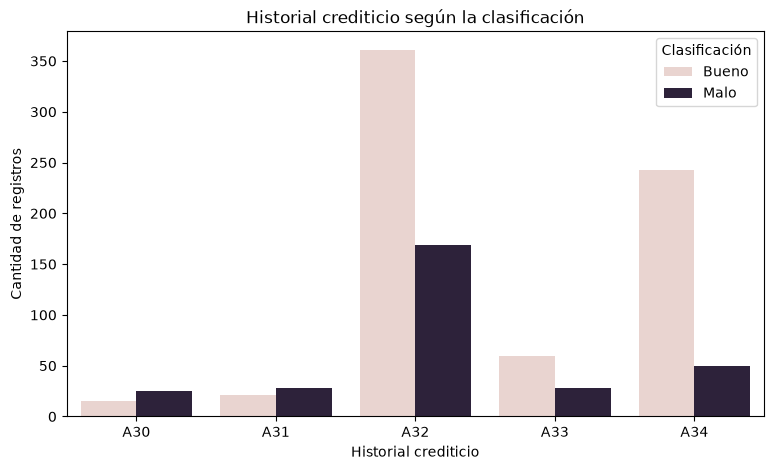

In [34]:
# Historial crediticio según la clasificación

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="historial_crediticio",
    hue="clase",
    order=sorted(df["historial_crediticio"].unique())
)

plt.title("Historial crediticio según la clasificación")
plt.xlabel("Historial crediticio")
plt.ylabel("Cantidad de registros")

plt.legend(
    title="Clasificación",
    labels=["Bueno", "Malo"]
)

plt.show()

In [35]:
# Porcentaje de créditos buenos y malos dentro de cada historial crediticio

porcentaje_historial = pd.crosstab(
    df["historial_crediticio"],
    df["clase"],
    normalize="index"
) * 100

porcentaje_historial.columns = ["Bueno (%)", "Malo (%)"]

porcentaje_historial.round(2)

,Bueno (%),Malo (%)
historial_crediticio,,
A30,37.50,62.50
A31,42.86,57.14
A32,68.11,31.89
A33,68.18,31.82
A34,82.94,17.06


### Interpretación del historial crediticio según la clase

Las categorías `A30` y `A31` presentan las mayores proporciones de créditos
malos, con 62,50 % y 57,14 %, respectivamente. Sin embargo, ambas categorías
contienen pocos registros en comparación con las demás.

La categoría `A32` contiene la mayor cantidad de registros del dataset. En esta
categoría se observan 361 créditos buenos y 169 créditos malos, equivalentes a
un 31,89 % de créditos malos.

La categoría `A33` presenta una proporción similar, con un 31,82 % de créditos
malos. Por otra parte, `A34` presenta la menor proporción de créditos malos,
con un 17,06 %.

Estos resultados muestran que el historial crediticio mantiene una relación
con la clasificación del crédito. También demuestran la importancia de revisar
porcentajes y no solamente cantidades, ya que las categorías contienen números
diferentes de registros.

### 3.6.3 Propósito del crédito

In [36]:
# Cantidad de registros según el propósito del crédito
df["proposito"].value_counts().sort_index()

proposito
A40     234
A41     103
A410     12
A42     181
A43     280
A44      12
A45      22
A46      50
A48       9
A49      97
Name: count, dtype: int64

### Propósito del crédito

La variable `proposito` indica la finalidad para la cual se solicitó el crédito:

- `A40`: automóvil nuevo.
- `A41`: automóvil usado.
- `A42`: muebles o equipo.
- `A43`: radio o televisión.
- `A44`: electrodomésticos.
- `A45`: reparaciones.
- `A46`: educación.
- `A47`: vacaciones.
- `A48`: capacitación.
- `A49`: negocio.
- `A410`: otros propósitos.

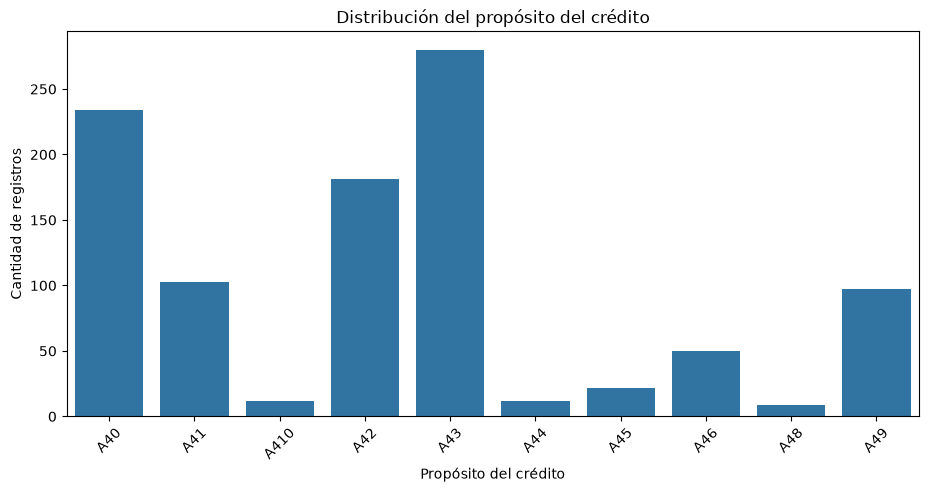

In [37]:
# Distribución del propósito del crédito

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="proposito",
    order=sorted(df["proposito"].unique())
)

plt.title("Distribución del propósito del crédito")
plt.xlabel("Propósito del crédito")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.show()

In [38]:
# Propósito del crédito según la clase

tabla_proposito = pd.crosstab(
    df["proposito"],
    df["clase"]
)

tabla_proposito.columns = ["Bueno", "Malo"]

tabla_proposito

,Bueno,Malo
proposito,,
A40,145,89
A41,86,17
A410,7,5
A42,123,58
A43,218,62
A44,8,4
A45,14,8
A46,28,22
A48,8,1


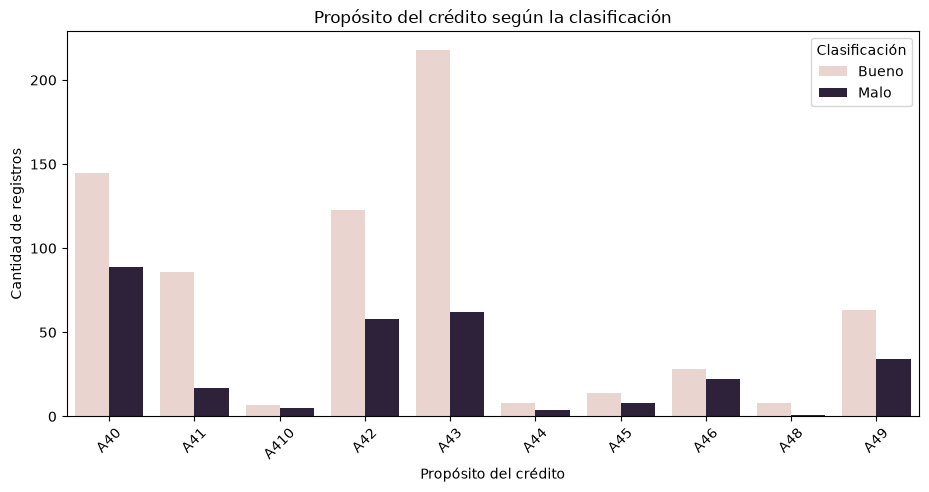

In [39]:
# Propósito del crédito según la clasificación

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="proposito",
    hue="clase",
    order=sorted(df["proposito"].unique())
)

plt.title("Propósito del crédito según la clasificación")
plt.xlabel("Propósito del crédito")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.legend(
    title="Clasificación",
    labels=["Bueno", "Malo"]
)

plt.show()

In [40]:
# Porcentaje de créditos buenos y malos dentro de cada propósito

porcentaje_proposito = pd.crosstab(
    df["proposito"],
    df["clase"],
    normalize="index"
) * 100

porcentaje_proposito.columns = ["Bueno (%)", "Malo (%)"]

porcentaje_proposito.round(2)

,Bueno (%),Malo (%)
proposito,,
A40,61.97,38.03
A41,83.50,16.50
A410,58.33,41.67
A42,67.96,32.04
A43,77.86,22.14
A44,66.67,33.33
A45,63.64,36.36
A46,56.00,44.00
A48,88.89,11.11


### Interpretación del propósito según la clase

Los propósitos más frecuentes son `A43`, radio o televisión, con 280 registros;
`A40`, automóvil nuevo, con 234 registros; y `A42`, muebles o equipo, con
181 registros.

La categoría `A46`, correspondiente a educación, presenta la mayor proporción
de créditos malos, con un 44,00 %. Le siguen `A410`, otros propósitos, con
41,67 %, y `A40`, automóvil nuevo, con 38,03 %.

Sin embargo, algunas categorías contienen pocos registros. Por ejemplo, `A410`
tiene solamente 12 casos y `A48` tiene 9. Por esta razón, sus porcentajes deben
interpretarse con precaución.

Entre las categorías con mayor cantidad de registros, `A40` presenta una
proporción de créditos malos de 38,03 %, mientras que `A43` presenta una
proporción de 22,14 %.

Los resultados muestran una relación entre el propósito del crédito y su
clasificación, pero no demuestran que el propósito sea por sí solo la causa
de una clasificación buena o mala.

### 3.6.4 Cuenta de ahorros

La variable `cuenta_ahorros` representa la condición de los ahorros o bonos
del cliente:

- `A61`: menos de 100.
- `A62`: entre 100 y 500.
- `A63`: entre 500 y 1.000.
- `A64`: igual o mayor que 1.000.
- `A65`: cuenta de ahorros desconocida o inexistente.

In [41]:
# Cantidad de registros según la cuenta de ahorros

df["cuenta_ahorros"].value_counts().sort_index()

cuenta_ahorros
A61    603
A62    103
A63     63
A64     48
A65    183
Name: count, dtype: int64

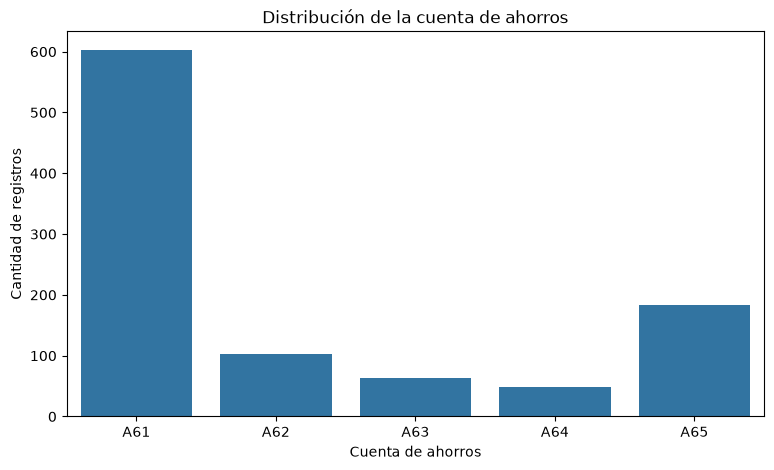

In [42]:
# Distribución de la cuenta de ahorros

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="cuenta_ahorros",
    order=sorted(df["cuenta_ahorros"].unique())
)

plt.title("Distribución de la cuenta de ahorros")
plt.xlabel("Cuenta de ahorros")
plt.ylabel("Cantidad de registros")

plt.show()

In [43]:
# Cuenta de ahorros según la clase

tabla_ahorros = pd.crosstab(
    df["cuenta_ahorros"],
    df["clase"]
)

tabla_ahorros.columns = ["Bueno", "Malo"]

tabla_ahorros

,Bueno,Malo
cuenta_ahorros,,
A61,386,217
A62,69,34
A63,52,11
A64,42,6
A65,151,32


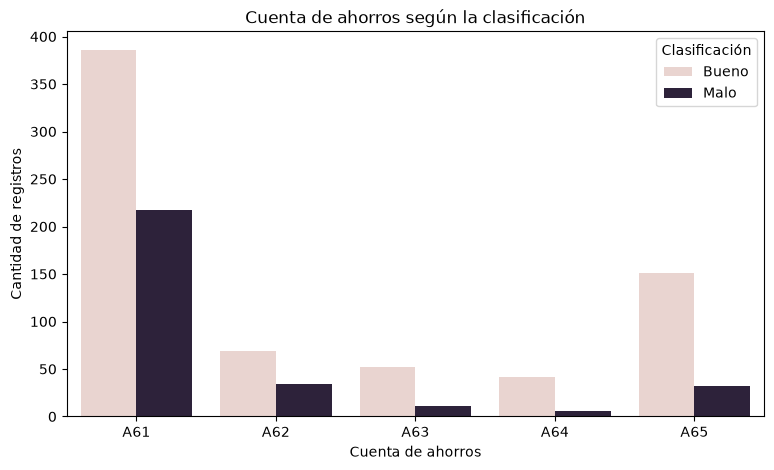

In [44]:
# Cuenta de ahorros según la clasificación

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="cuenta_ahorros",
    hue="clase",
    order=sorted(df["cuenta_ahorros"].unique())
)

plt.title("Cuenta de ahorros según la clasificación")
plt.xlabel("Cuenta de ahorros")
plt.ylabel("Cantidad de registros")

plt.legend(
    title="Clasificación",
    labels=["Bueno", "Malo"]
)

plt.show()

In [45]:
# Porcentaje de créditos buenos y malos dentro de cada cuenta de ahorros

porcentaje_ahorros = pd.crosstab(
    df["cuenta_ahorros"],
    df["clase"],
    normalize="index"
) * 100

porcentaje_ahorros.columns = ["Bueno (%)", "Malo (%)"]

porcentaje_ahorros.round(2)

,Bueno (%),Malo (%)
cuenta_ahorros,,
A61,64.01,35.99
A62,66.99,33.01
A63,82.54,17.46
A64,87.50,12.50
A65,82.51,17.49


### Interpretación de la cuenta de ahorros según la clase

La categoría `A61`, correspondiente a ahorros inferiores a 100, contiene la
mayor cantidad de registros y presenta un 35,99 % de créditos malos.

La categoría `A62`, ahorros entre 100 y 500, presenta una proporción similar,
con un 33,01 % de créditos malos.

Las categorías `A63` y `A64`, asociadas con mayores cantidades de ahorro,
presentan proporciones menores de créditos malos, con 17,46 % y 12,50 %,
respectivamente.

La categoría `A65`, correspondiente a una cuenta de ahorros desconocida o
inexistente, presenta un 17,49 % de créditos malos.

Dentro de este dataset se observa una relación entre la condición de los
ahorros y la clasificación del crédito. Sin embargo, estos resultados no
demuestran que la cuenta de ahorros sea por sí sola la causa de una
clasificación buena o mala.

## 3.7 Matriz de correlación de las variables numéricas

La matriz de correlación permite observar la relación lineal entre las
variables numéricas.

Los valores cercanos a 1 representan una relación positiva, los valores
cercanos a -1 representan una relación negativa y los valores cercanos a 0
indican una relación lineal débil.

In [46]:
# Selección de las variables numéricas

columnas_numericas = [
    "duracion_meses",
    "monto_credito",
    "tasa_cuotas",
    "tiempo_residencia",
    "edad",
    "creditos_existentes",
    "personas_dependientes"
]

df_numerico = df[columnas_numericas]

df_numerico.head()

,duracion_meses,monto_credito,tasa_cuotas,tiempo_residencia,edad,creditos_existentes,personas_dependientes
0,6,1169,4,4,67,2,1
1,48,5951,2,2,22,1,1
2,12,2096,2,3,49,1,2
3,42,7882,2,4,45,1,2
4,24,4870,3,4,53,2,2


In [47]:
# Cálculo de la matriz de correlación

matriz_correlacion = df_numerico.corr()

matriz_correlacion

,duracion_meses,monto_credito,tasa_cuotas,tiempo_residencia,edad,creditos_existentes,personas_dependientes
duracion_meses,1.000000,0.624984,0.074749,0.034067,-0.036136,-0.011284,-0.023834
monto_credito,0.624984,1.000000,-0.271316,0.028926,0.032716,0.020795,0.017142
tasa_cuotas,0.074749,-0.271316,1.000000,0.049302,0.058266,0.021669,-0.071207
tiempo_residencia,0.034067,0.028926,0.049302,1.000000,0.266419,0.089625,0.042643
edad,-0.036136,0.032716,0.058266,0.266419,1.000000,0.149254,0.118201
creditos_existentes,-0.011284,0.020795,0.021669,0.089625,0.149254,1.000000,0.109667
personas_dependientes,-0.023834,0.017142,-0.071207,0.042643,0.118201,0.109667,1.000000


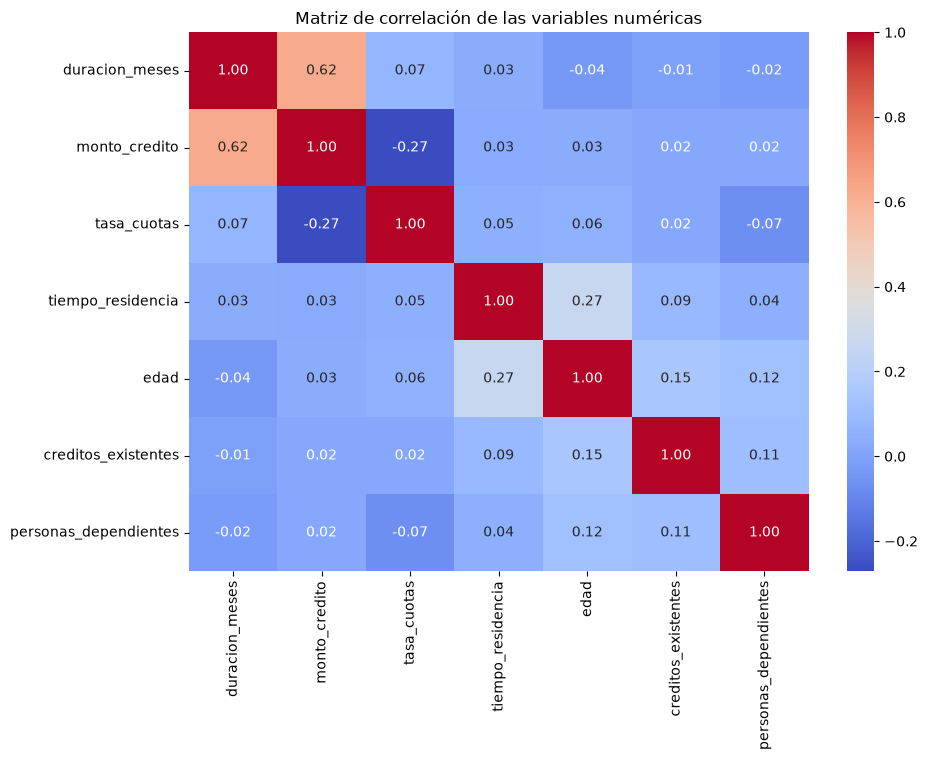

In [48]:
# Mapa de calor de la matriz de correlación

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de las variables numéricas")

plt.show()

### Interpretación de la matriz de correlación

La relación lineal más destacada se observa entre `duracion_meses` y
`monto_credito`, con una correlación positiva aproximada de 0,62. Esto indica
que, dentro del dataset, los créditos de mayor monto tienden a presentar una
duración más extensa.

También se observa una correlación negativa de aproximadamente -0,27 entre
`monto_credito` y `tasa_cuotas`. Por otra parte, `tiempo_residencia` y `edad`
presentan una correlación positiva aproximada de 0,27.

Las demás relaciones presentan valores cercanos a cero, por lo que muestran
relaciones lineales débiles.

La correlación permite identificar relaciones entre variables, pero no
demuestra que una variable sea la causa de los cambios observados en otra.

## 3.8 Conclusiones generales del EDA

El conjunto German Credit contiene 1.000 registros, 20 variables de entrada
y una variable objetivo. No se encontraron valores nulos ni registros
duplicados, por lo que no fue necesario eliminar observaciones durante el
análisis exploratorio.

La variable objetivo presenta 700 créditos buenos y 300 créditos malos. Esto
representa una distribución de 70 % y 30 %, respectivamente. Debido a este
desbalance, la evaluación de los modelos no deberá basarse únicamente en la
exactitud.

Los créditos malos presentan una duración y un monto promedio superiores a
los créditos buenos. También se observa que los clientes asociados con créditos
malos tienen una edad promedio ligeramente menor. Estas diferencias representan
relaciones observadas y no causas directas de la clasificación.

Entre las variables categóricas analizadas, el estado de la cuenta corriente,
el historial crediticio, el propósito del crédito y la condición de los ahorros
presentan diferencias en la proporción de créditos buenos y malos.

La correlación numérica más destacada se observa entre la duración y el monto
del crédito, con un valor aproximado de 0,62. La mayoría de las demás relaciones
lineales son débiles.

Para preparar los datos para las redes neuronales será necesario convertir las
variables categóricas mediante variables dummy, transformar la variable objetivo
y normalizar las variables numéricas. Estas operaciones se realizarán en el
notebook de preprocesamiento para mantener separado el análisis exploratorio.